# Module 05 — Practice Project, Lab 01
**Xiaoyu Guo · MC648131**

Completed individually. The original questions are retained below. Instructor hints and example solutions remain in the untouched original notebook; the code, outputs and interpretations here are my completed work. Data are loaded from `../data/`. These are descriptive analyses, not estimates of causal effects. The automobile dataset is synthetic.

# **Practice Assignment - Part 1: Analyzing wildfire activities in Australia** 

Estimated time needed: **40** minutes


# __Table of Contents__

<ol>
    <li><a href="#Objectives">Objectives</a></li>
    <li>
        <a href="#Setup">Setup</a>
        <ol>
            <li><a href="#Installing-Required-Libraries">Installing Required Libraries</a></li>
            <li><a href="#Importing-Required-Libraries">Importing Required Libraries</a></li>
    </li>
    <li>
        <a href="#Dataset">Dataset</a>
    </li>
    <li><a href="#Importing Dataset">Importing Dataset</a></li>
    <li><a href="#Practice Tasks">Practice Tasks</a></li>
   


---


# Objectives

After completing this lab you will be able to:

 - Use visualization libraries such as Matplotlib, Pandas, Seaborn and Folium to create informative plots and charts 


---


# Setup


For this lab, we will be using the following libraries:

*   [`pandas`](https://pandas.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for managing the data.
*   [`numpy`](https://numpy.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for mathematical operations.
*   [`seaborn`](https://seaborn.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for visualizing the data.
*   [`matplotlib`](https://matplotlib.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for additional plotting tools.


### Installing Required Libraries

The following required libraries are pre-installed in the Skills Network Labs environment. However, if you run this notebook commands in a different Jupyter environment (e.g. Watson Studio or Ananconda), you will need to install these libraries by removing the `#` sign before `%pip` in the code cell below.


In [1]:
# Dependencies are installed in the documented Python environment; no installation is needed during execution.

In [2]:
# See requirements.txt in this folder.

### Importing Required Libraries

_We recommend you import all required libraries in one place (here):_


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from IPython.display import display, Markdown
%matplotlib inline
sns.set_theme(style="whitegrid", palette="colorblind")
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("svg", "png")
plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 180,
    "font.size": 18, "axes.titlesize": 20, "axes.labelsize": 18,
    "xtick.labelsize": 16, "ytick.labelsize": 16,
    "legend.fontsize": 16, "legend.title_fontsize": 16,
    "svg.fonttype": "none"
})
DATA = Path("../data")

---


# Dataset

**Historical Wildfires**

This wildfire dataset contains data on fire activities in Australia starting from 2005. Additional information can be found [here](https://earthdata.nasa.gov/earth-observation-data/near-real-time/firms/c6-mcd14dl).

Variables

- Region: the 7 regions
- Date: in UTC and provide the data for 24 hours ahead
- Estimated_fire_area: daily sum of estimated fire area for presumed vegetation fires with a confidence > 75% for a each region in km2
- Mean_estimated_fire_brightness: daily mean (by flagged fire pixels(=count)) of estimated fire brightness for presumed vegetation fires with a confidence level > 75% in Kelvin
- Mean_estimated_fire_radiative_power: daily mean of estimated radiative power for presumed vegetation fires with a confidence level > 75% for a given region in megawatts
- Mean_confidence: daily mean of confidence for presumed vegetation fires with a confidence level > 75%
- Std_confidence: standard deviation of estimated fire radiative power in megawatts
- Var_confidence: Variance of estimated fire radiative power in megawatts
- Count: daily numbers of pixels for presumed vegetation fires with a confidence level of larger than 75% for a given region
- Replaced: Indicates with an Y whether the data has been replaced with standard quality data when they are available (usually with a 2-3 month lag). Replaced data has a slightly higher quality in terms of locations


---


### Importing Data


In [4]:
df = pd.read_csv(DATA / "Historical_Wildfires.csv")
print(f"Loaded {len(df):,} daily region observations from the local CSV.")
print("Missing values by affected column:")
print(df.isna().sum().loc[lambda counts: counts > 0].to_string())
assert not df[["Date", "Region", "Estimated_fire_area", "Mean_estimated_fire_brightness", "Mean_estimated_fire_radiative_power", "Mean_confidence", "Count"]].isna().any().any()
print("All fields used in the analyses are complete; unused missing fields are left unchanged.")

Loaded 26,406 daily region observations from the local CSV.
Missing values by affected column:
Std_confidence    2207
Var_confidence    2207
All fields used in the analyses are complete; unused missing fields are left unchanged.


Let's look at some samples rows from the dataset we loaded:


In [5]:
df.head()

,Region,Date,Estimated_fire_area,Mean_estimated_fire_brightness,Mean_estimated_fire_radiative_power,Mean_confidence,Std_confidence,Var_confidence,Count,Replaced
0,NSW,1/4/2005,8.68000,312.266667,42.400000,78.666667,2.886751,8.333333,3,R
1,NSW,1/5/2005,16.61125,322.475000,62.362500,85.500000,8.088793,65.428571,8,R
2,NSW,1/6/2005,5.52000,325.266667,38.400000,78.333333,3.214550,10.333333,3,R
3,NSW,1/7/2005,6.26400,313.870000,33.800000,92.200000,7.529940,56.700000,5,R
4,NSW,1/8/2005,5.40000,337.383333,122.533333,91.000000,7.937254,63.000000,3,R


---


Let's verify the column names and the data type of each variable


In [6]:
#Column names
df.columns

Index(['Region', 'Date', 'Estimated_fire_area',
       'Mean_estimated_fire_brightness', 'Mean_estimated_fire_radiative_power',
       'Mean_confidence', 'Std_confidence', 'Var_confidence', 'Count',
       'Replaced'],
      dtype='str')

In [7]:
#data type
df.dtypes

Region                                     str
Date                                       str
Estimated_fire_area                    float64
Mean_estimated_fire_brightness         float64
Mean_estimated_fire_radiative_power    float64
Mean_confidence                        float64
Std_confidence                         float64
Var_confidence                         float64
Count                                    int64
Replaced                                   str
dtype: object

Notice the type of 'Date' is object, let's convert it to 'datatime' type and also let's extract 'Year' and 'Month' from date and include in the dataframe as separate columns


In [8]:
df["Date"] = pd.to_datetime(df["Date"])
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
print("Coverage:", df["Date"].min().date(), "to", df["Date"].max().date())

Coverage: 2005-01-01 to 2020-10-31


**Verify the columns again**


In [9]:
display(df[["Date", "Year", "Month", "Region"]].head())

,Date,Year,Month,Region
0,2005-01-04,2005,1,NSW
1,2005-01-05,2005,1,NSW
2,2005-01-06,2005,1,NSW
3,2005-01-07,2005,1,NSW
4,2005-01-08,2005,1,NSW


---


## Practice Tasks


### TASK 1.1: Let's try to understand the change in average estimated fire area over time <br>(use pandas to plot)


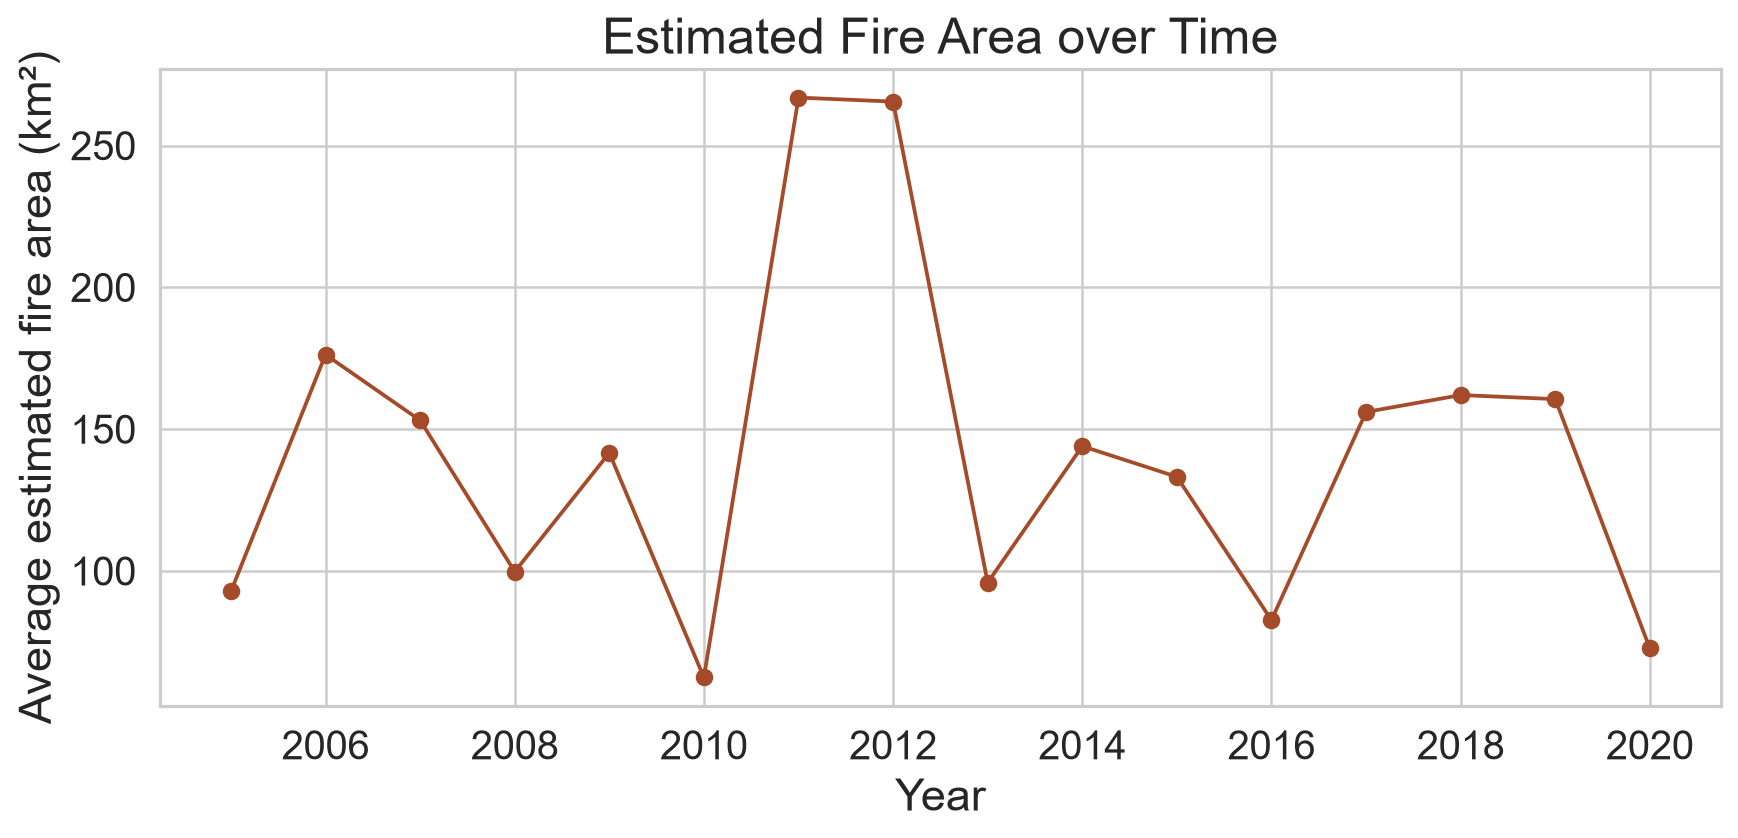

The highest annual daily-region average is 266.94 km² in 2011.
This is an average across observations, not the annual total burned area. The final year is incomplete.


In [10]:
annual_area = df.groupby("Year")["Estimated_fire_area"].mean()
annual_area.plot(kind="line", marker="o", color="#a64b2a")
plt.xlabel("Year"); plt.ylabel("Average estimated fire area (km²)")
plt.title("Estimated Fire Area over Time")
plt.tight_layout(); plt.show()
print(f"The highest annual daily-region average is {annual_area.max():.2f} km² in {annual_area.idxmax()}.")
print("This is an average across observations, not the annual total burned area. The final year is incomplete.")

---


### TASK 1.2: You can notice the peak in the plot between 2010 to 2013. Let's narrow down our finding, by plotting the estimated fire area for year grouped together with month.


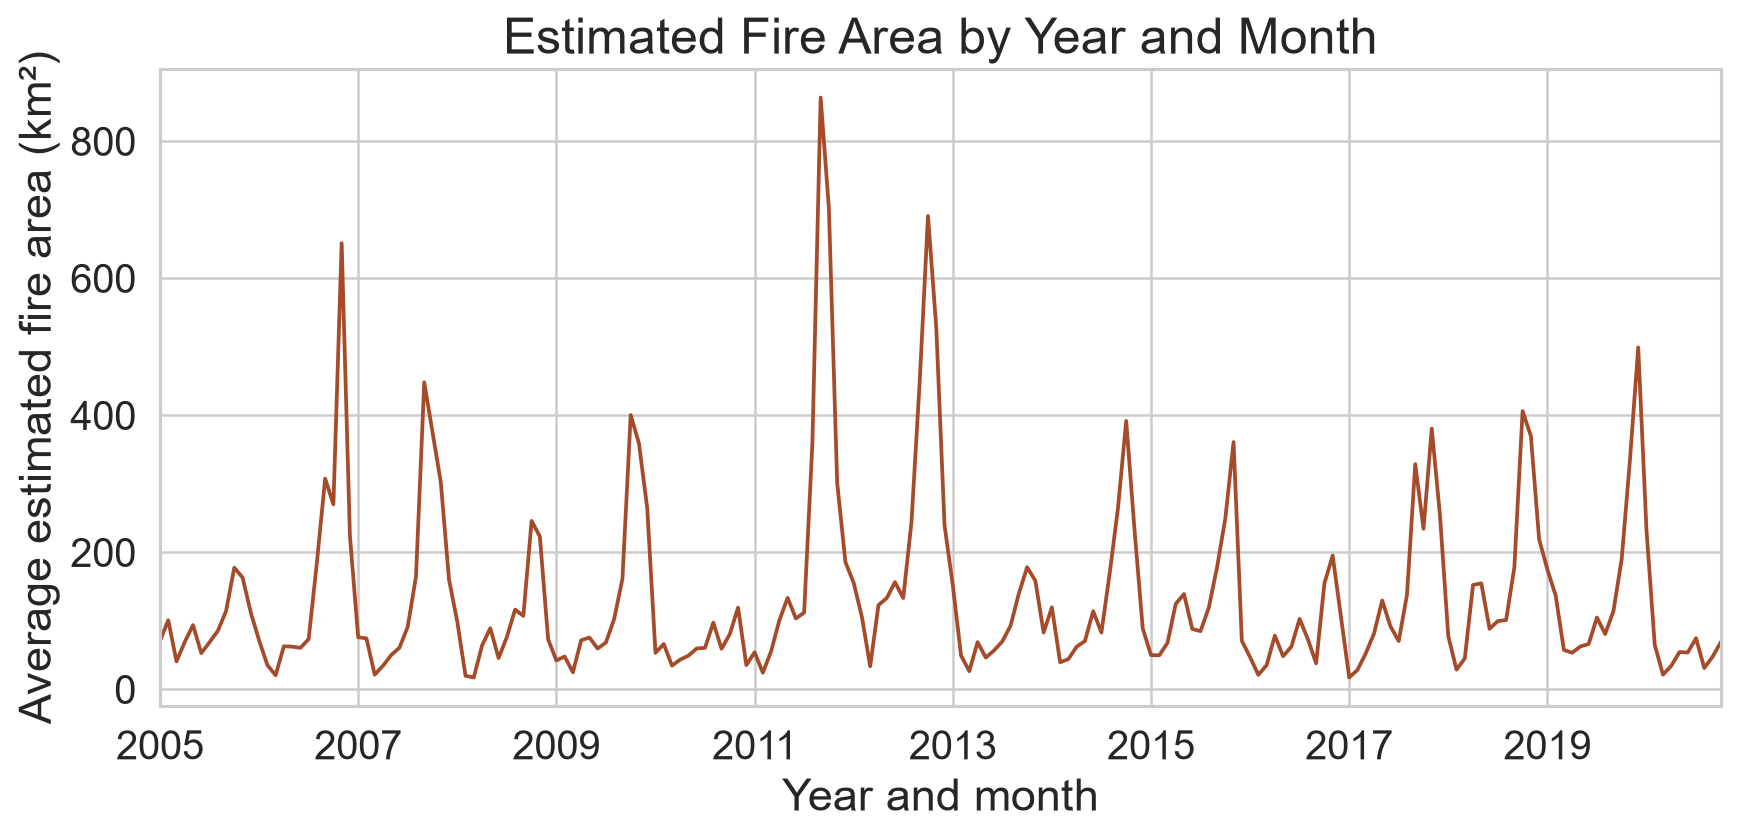

The largest monthly average is 863.79 km² in September 2011.
The monthly series exposes short seasonal peaks hidden by annual averaging.


In [11]:
monthly_area = df.groupby(["Year", "Month"])["Estimated_fire_area"].mean()
monthly_area.index = pd.to_datetime([f"{y}-{m:02d}-01" for y, m in monthly_area.index])
monthly_area.plot(kind="line", color="#a64b2a")
plt.xlabel("Year and month"); plt.ylabel("Average estimated fire area (km²)")
plt.title("Estimated Fire Area by Year and Month")
plt.tight_layout(); plt.show()
print(f"The largest monthly average is {monthly_area.max():.2f} km² in {monthly_area.idxmax():%B %Y}.")
print("The monthly series exposes short seasonal peaks hidden by annual averaging.")

---


### TASK 1.3: Let's have an insight on the distribution of mean estimated fire brightness across the regions<br> use the functionality of seaborn to develop a barplot


before starting with the plot, why not know the regions mentioned in the dataset?. <br>Make use of unique() to identify the regions in the dataset (apply it on series only)


In [12]:
df['Region'].unique()

<StringArray>
['NSW', 'NT', 'QL', 'SA', 'TA', 'VI', 'WA']
Length: 7, dtype: str

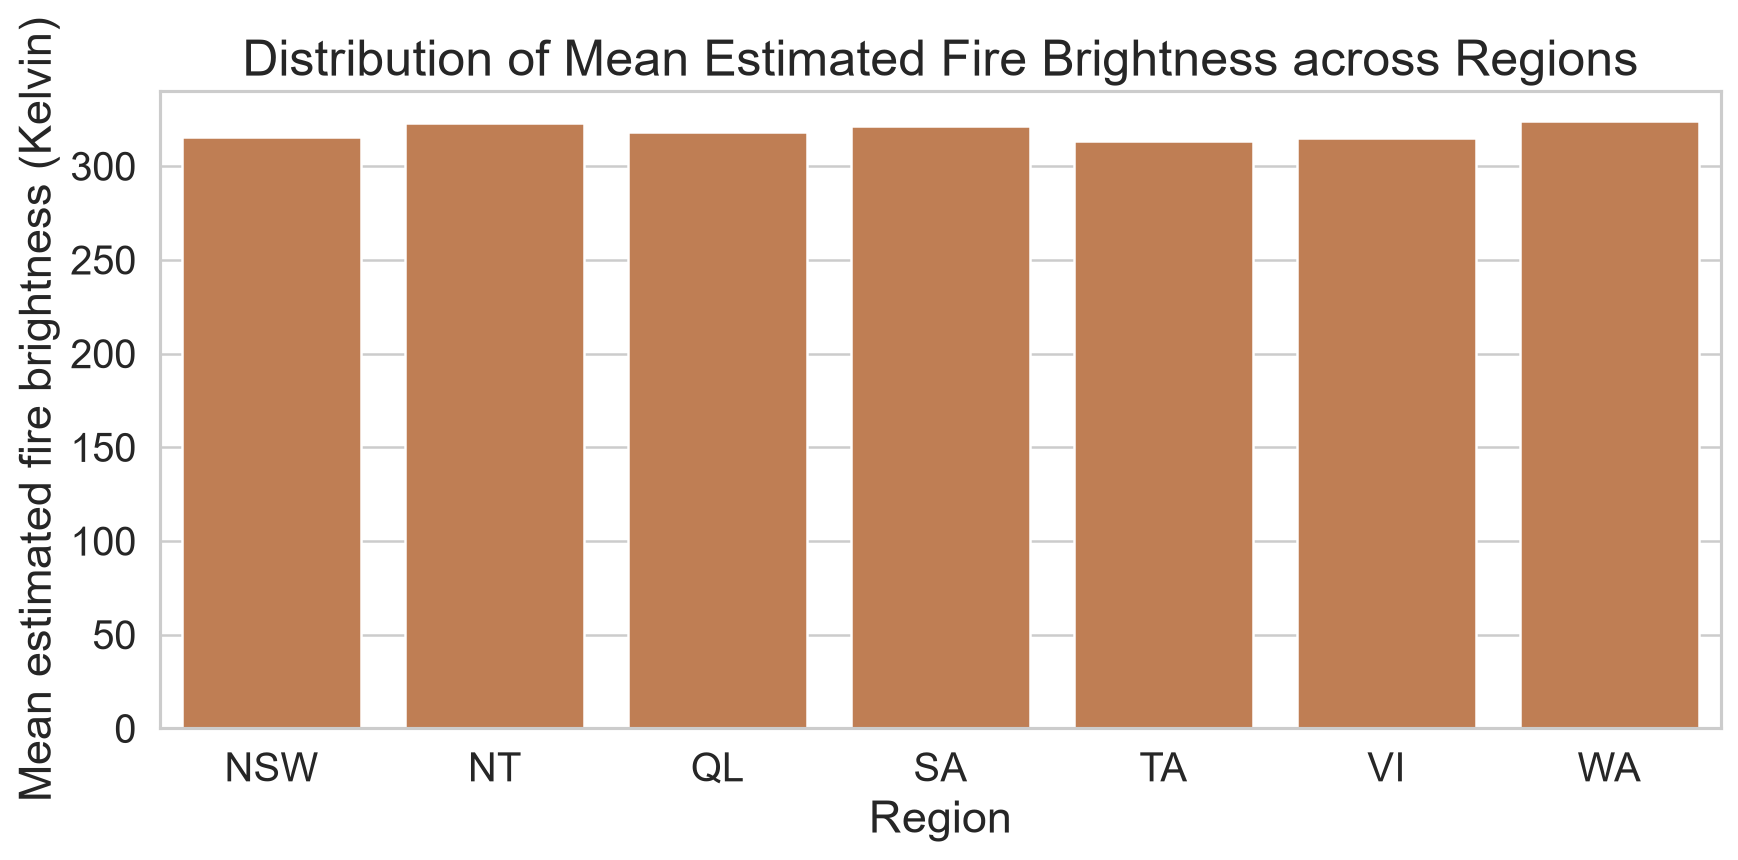

WA has the highest daily mean brightness (324.14 K); TA has the lowest (313.37 K).
These are unweighted averages of daily means, so they do not weight days by the number of fire pixels.


In [13]:
region_order = sorted(df["Region"].unique())
sns.barplot(data=df, x="Region", y="Mean_estimated_fire_brightness", order=region_order, errorbar=None, color="#d17a42")
plt.xlabel("Region"); plt.ylabel("Mean estimated fire brightness (Kelvin)")
plt.title("Distribution of Mean Estimated Fire Brightness across Regions")
plt.tight_layout(); plt.show()
brightness = df.groupby("Region")["Mean_estimated_fire_brightness"].mean()
print(f"{brightness.idxmax()} has the highest daily mean brightness ({brightness.max():.2f} K); {brightness.idxmin()} has the lowest ({brightness.min():.2f} K).")
print("These are unweighted averages of daily means, so they do not weight days by the number of fire pixels.")

---


### TASK 1.4: Let's find the portion of count of pixels for presumed vegetation fires vary across regions<br> we will develop a pie chart for this


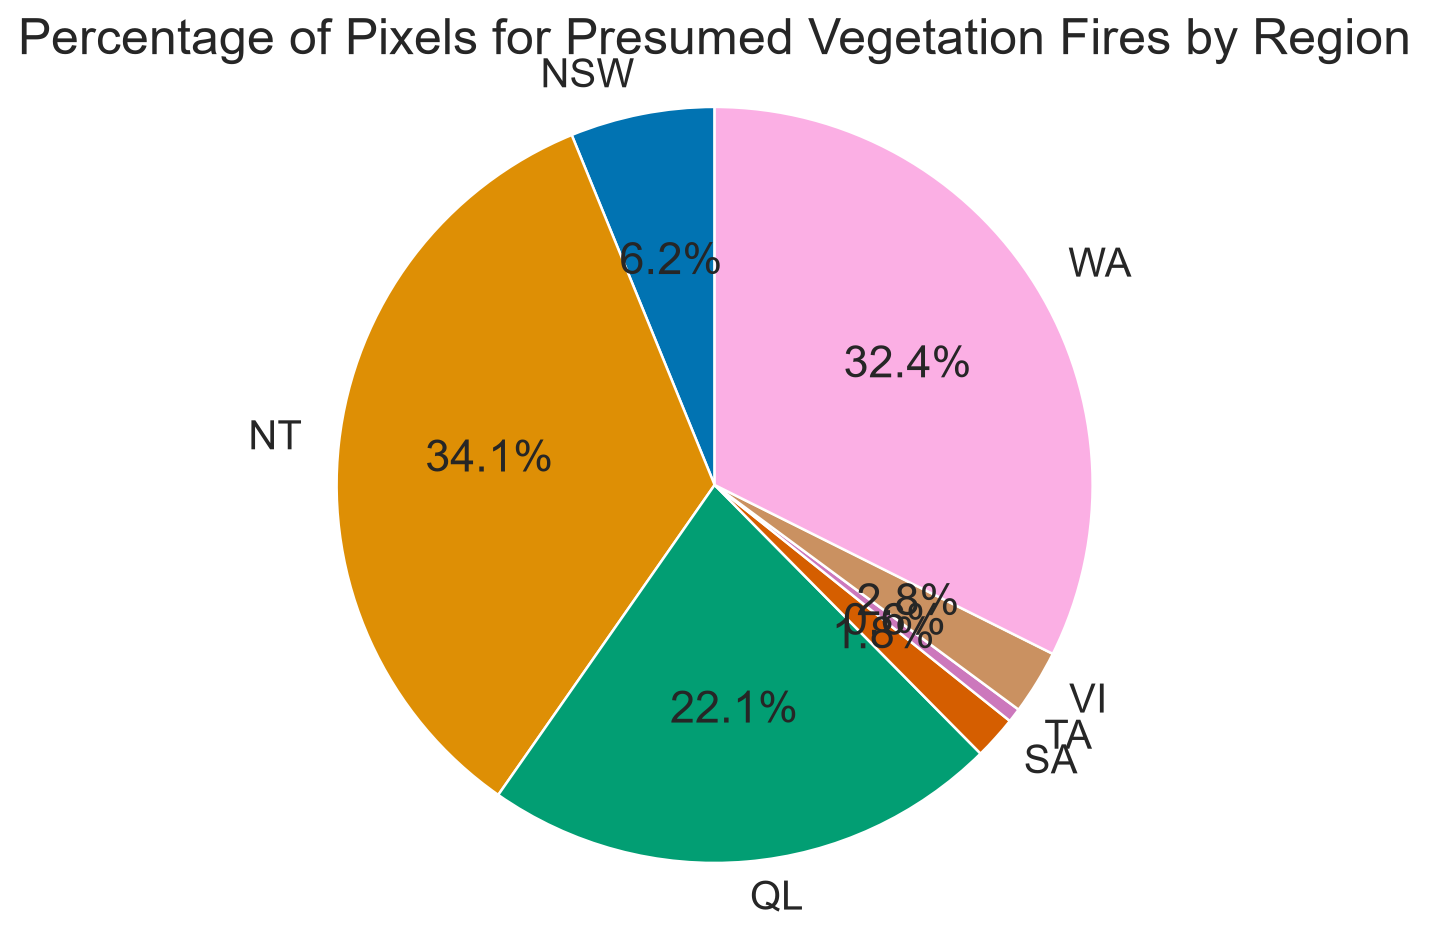

In [14]:
region_counts = df.groupby("Region")["Count"].sum()
plt.figure(figsize=(8, 6))
plt.pie(region_counts, labels=region_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Percentage of Pixels for Presumed Vegetation Fires by Region")
plt.axis("equal"); plt.show()

### TASK 1.5: See the percentage on the pie is not looking so good as it is overlaped for Region SA, TA, VI 

remove the autopct from pie function and pass the following to plt.legend() after plt.title() <br>
`[(i,round(k/region_counts.sum()*100,2)) for i,k in zip(region_counts.index, region_counts)]`


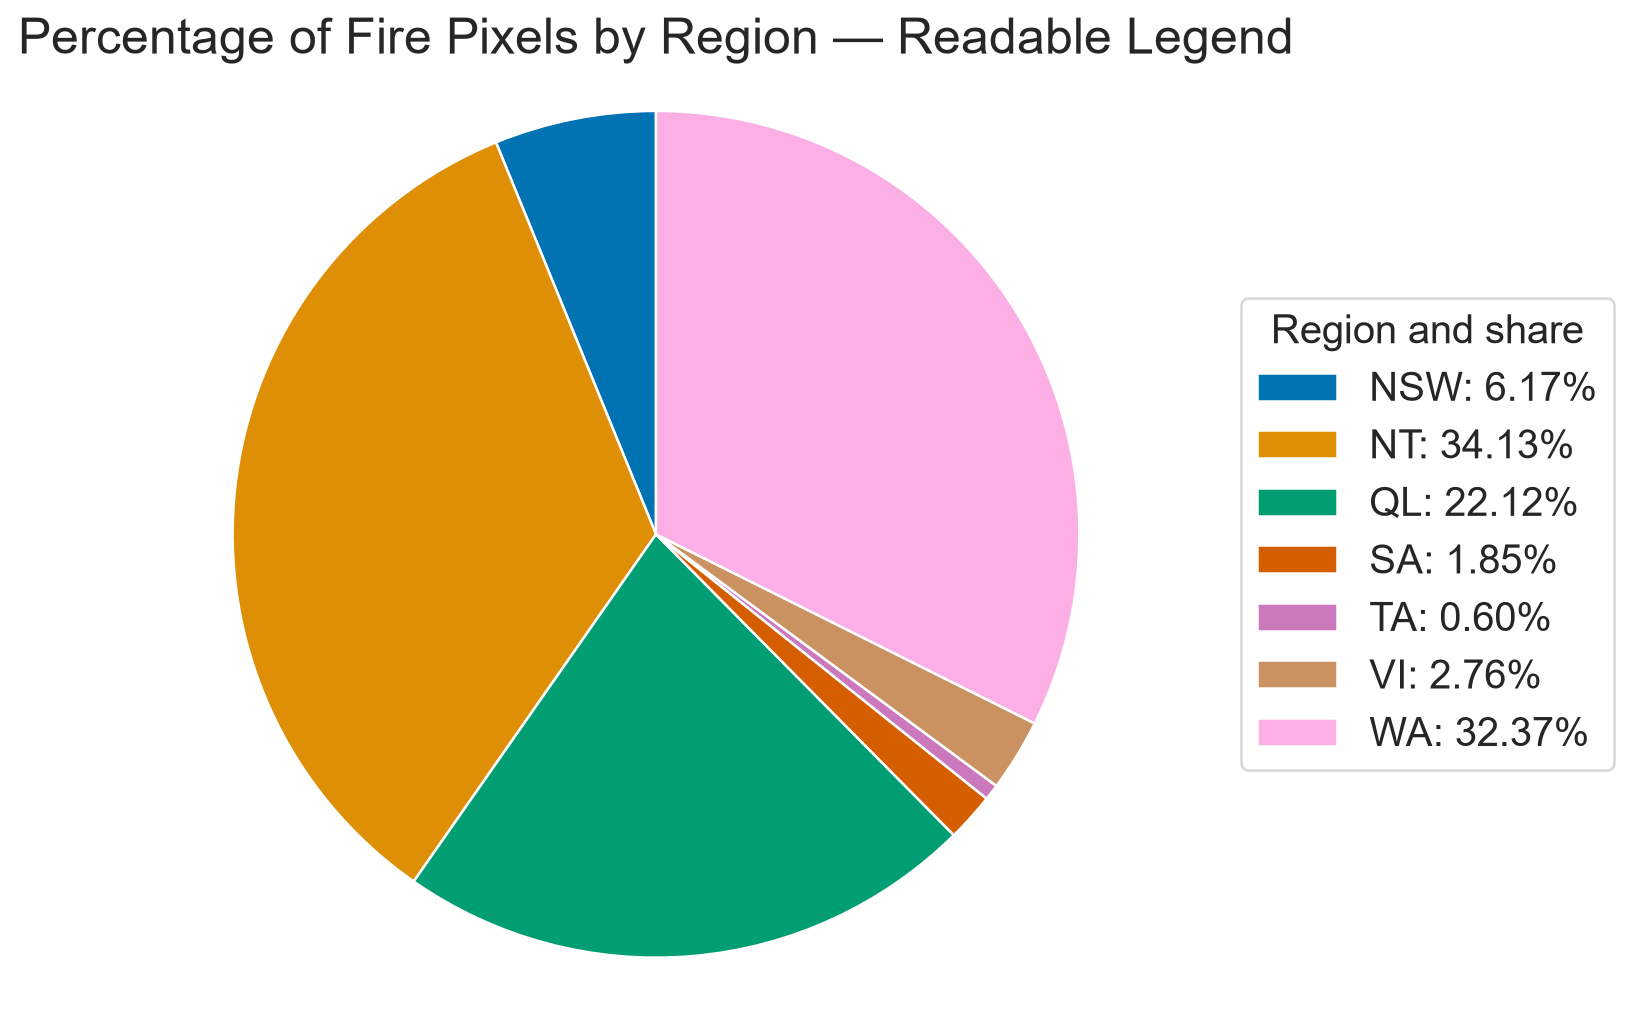

NT contributes 34.13% of recorded fire pixels. The three smallest shares total 5.21%.
Pixel counts measure detected fire pixels, not the number of distinct fires.


In [15]:
plt.figure(figsize=(9, 6))
wedges, _ = plt.pie(region_counts, startangle=90)
shares = region_counts / region_counts.sum() * 100
plt.legend(wedges, [f"{region}: {share:.2f}%" for region, share in shares.items()], title="Region and share", loc="center left", bbox_to_anchor=(1, 0.5))
plt.title("Percentage of Fire Pixels by Region — Readable Legend")
plt.axis("equal"); plt.tight_layout(); plt.show()
print(f"{shares.idxmax()} contributes {shares.max():.2f}% of recorded fire pixels. The three smallest shares total {shares.nsmallest(3).sum():.2f}%.")
print("Pixel counts measure detected fire pixels, not the number of distinct fires.")

---


### TASK 1.6: Let's try to develop a histogram of the mean estimated fire brightness<br> Using Matplotlib to create the histogram


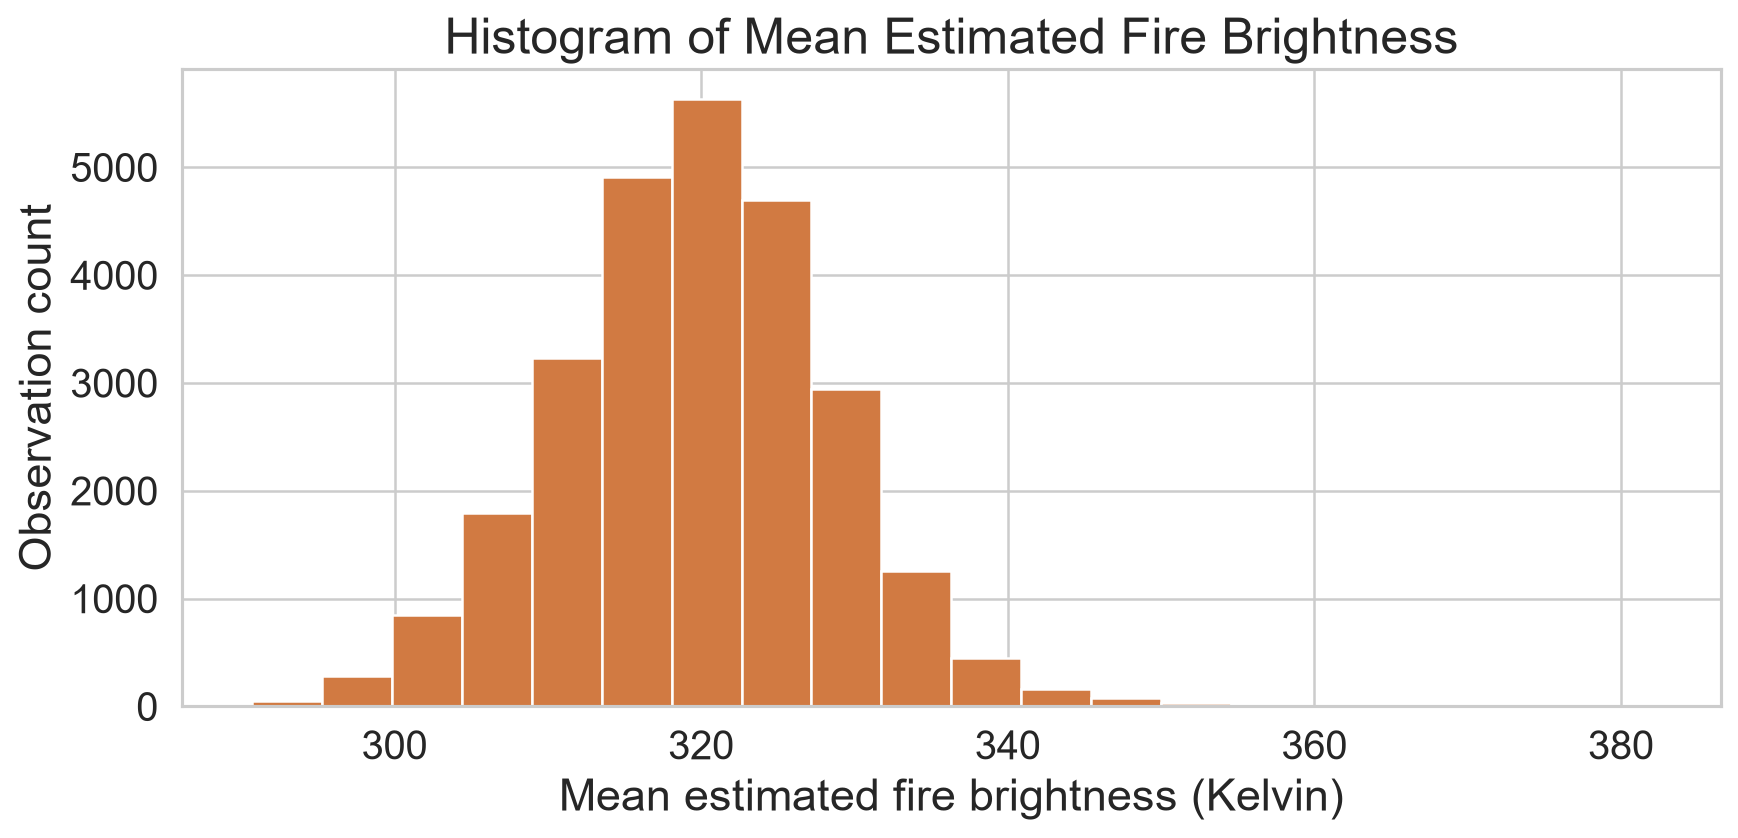

count    26406.00
mean       319.66
std          8.86
min        290.70
25%        313.93
50%        319.78
75%        325.40
max        381.95


In [16]:
plt.hist(df["Mean_estimated_fire_brightness"], bins=20, color="#d17a42", edgecolor="white")
plt.xlabel("Mean estimated fire brightness (Kelvin)"); plt.ylabel("Observation count")
plt.title("Histogram of Mean Estimated Fire Brightness")
plt.tight_layout(); plt.show()
print(df["Mean_estimated_fire_brightness"].describe().round(2).to_string())

### TASK 1.7: What if we need to understand the distribution of estimated fire brightness across regions? Let's use the functionality of seaborn and  pass region as hue


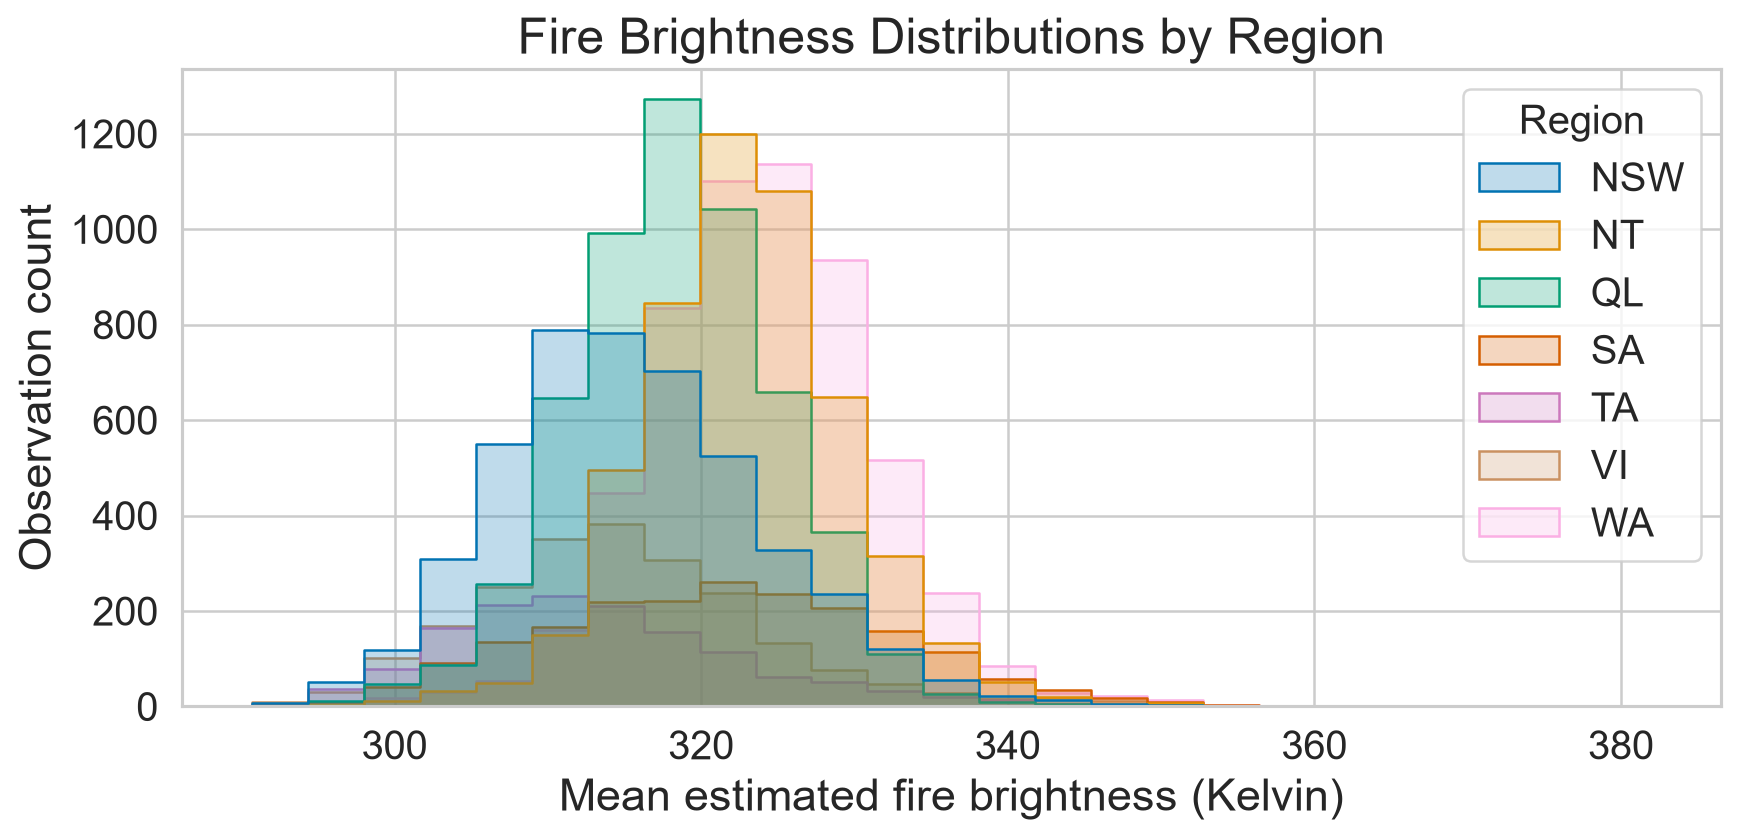

In [17]:
sns.histplot(data=df, x="Mean_estimated_fire_brightness", hue="Region", hue_order=region_order, bins=25, element="step", alpha=.25)
plt.xlabel("Mean estimated fire brightness (Kelvin)"); plt.ylabel("Observation count")
plt.title("Fire Brightness Distributions by Region")
plt.tight_layout(); plt.show()

### looks better!, now include the parameter `multiple='stack'` in the histplot() and see the difference. Include labels and titles as well


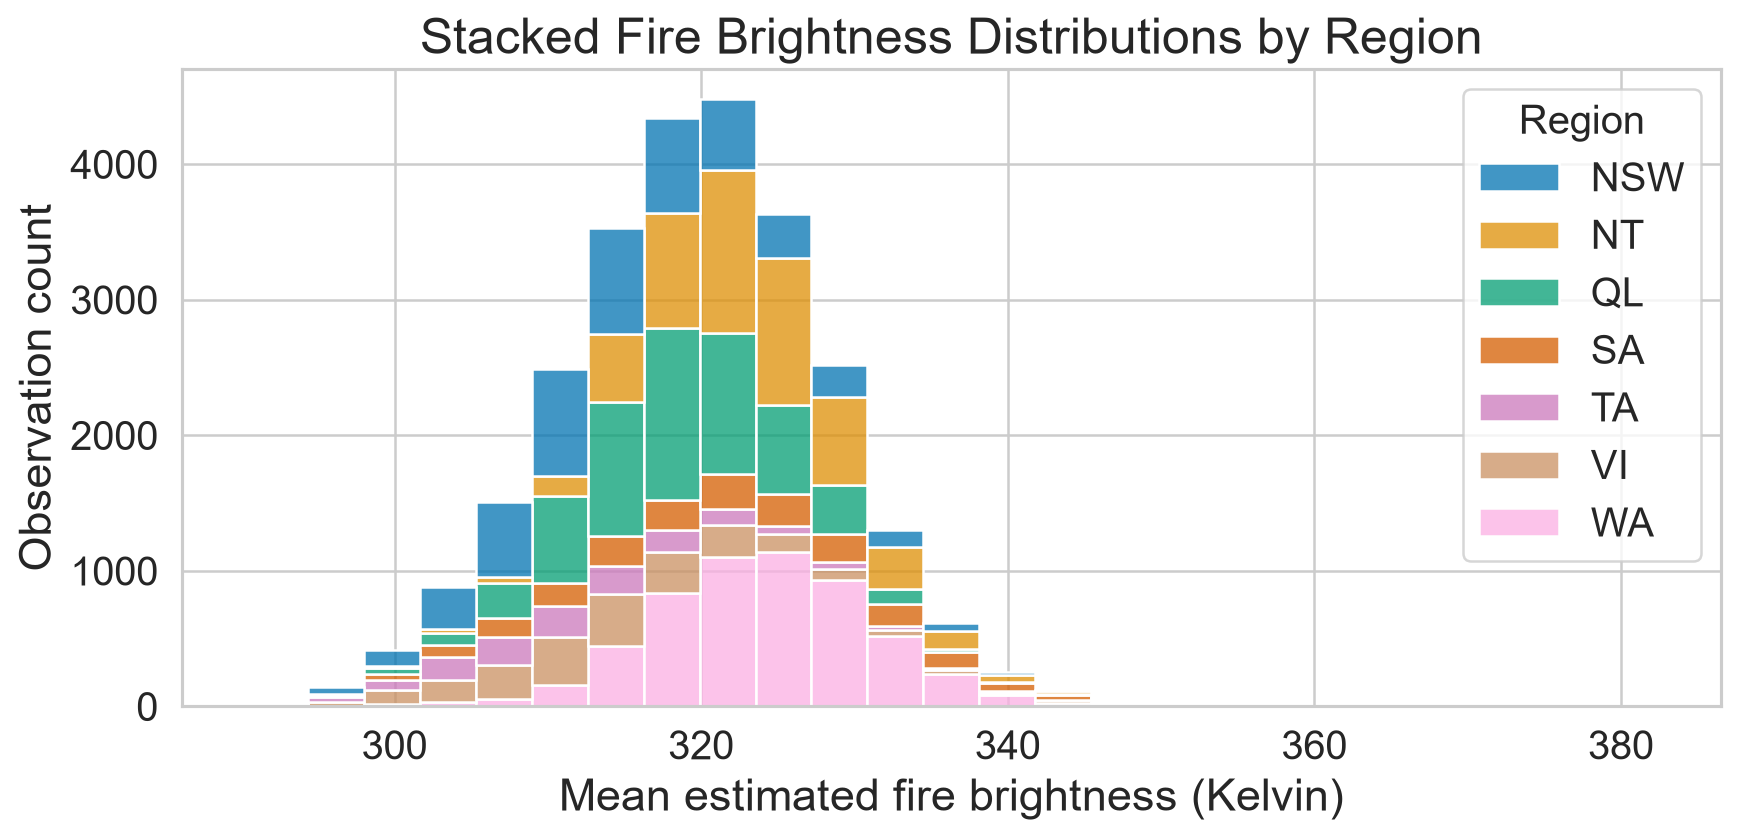

Stacking makes the combined frequency visible, while the overlaid version is better for comparing shapes. Both use counts, so regions with more observations occupy more area.


In [18]:
sns.histplot(data=df, x="Mean_estimated_fire_brightness", hue="Region", hue_order=region_order, multiple="stack", bins=25)
plt.xlabel("Mean estimated fire brightness (Kelvin)"); plt.ylabel("Observation count")
plt.title("Stacked Fire Brightness Distributions by Region")
plt.tight_layout(); plt.show()
print("Stacking makes the combined frequency visible, while the overlaid version is better for comparing shapes. Both use counts, so regions with more observations occupy more area.")

---


### TASK 1.8: Let's try to find if there is any correlation between mean estimated fire radiative power and mean confidence level?


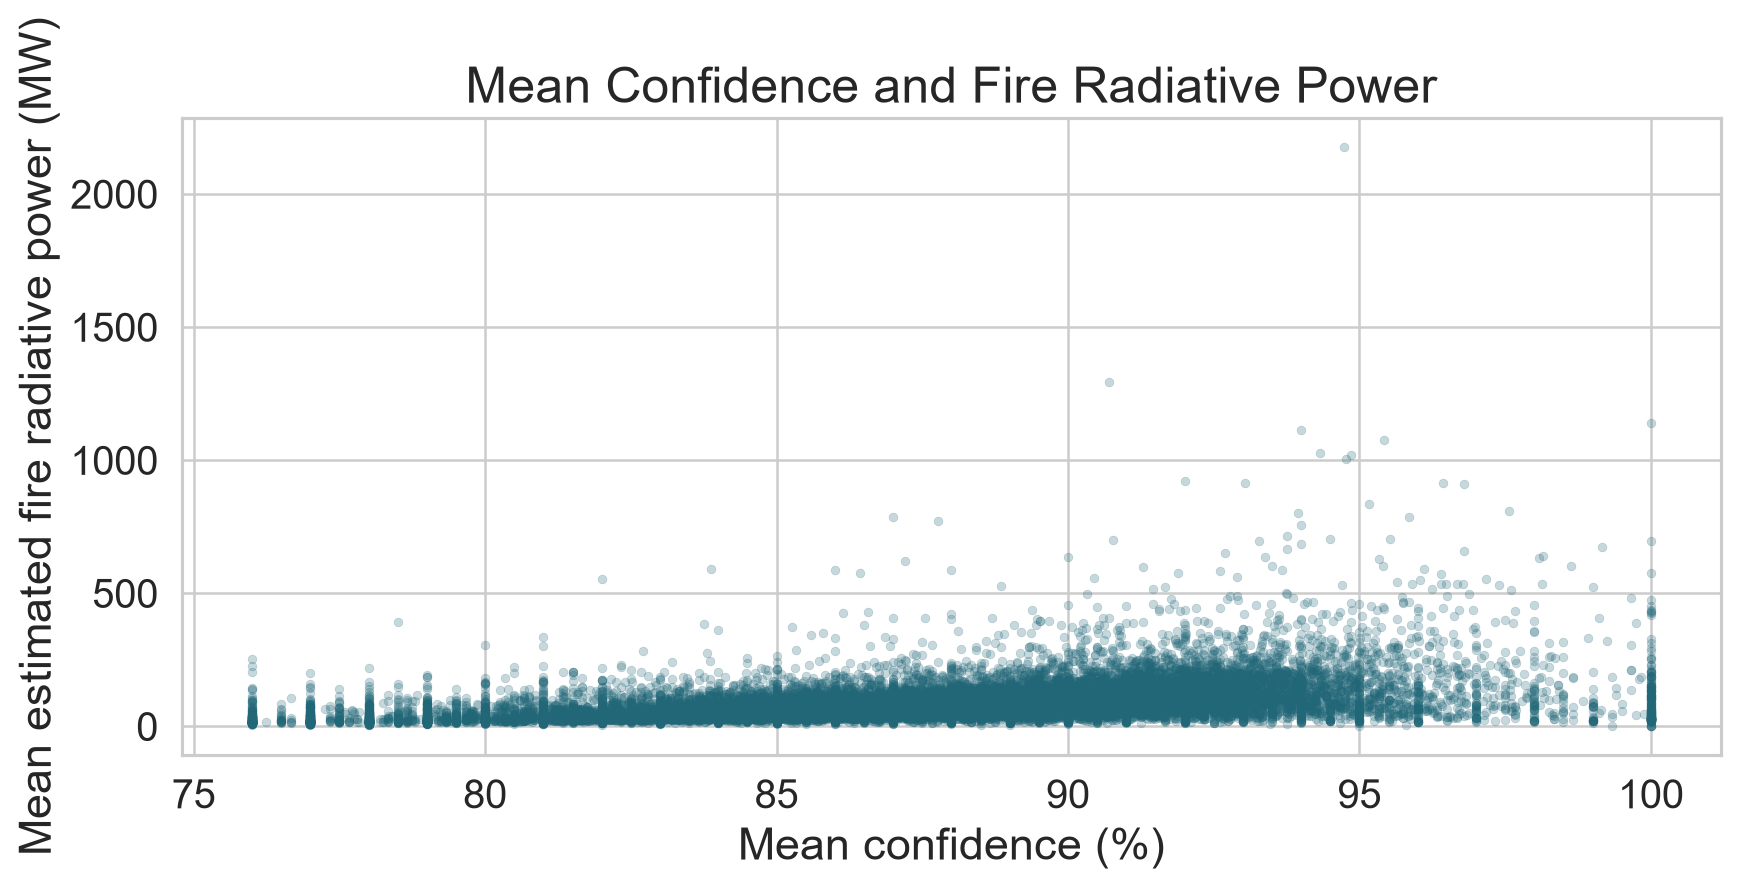

Pearson correlation across daily region observations: 0.452.
The positive correlation is moderate: higher-confidence observations tend to have higher radiative power, but the points remain widely scattered. A few high-power observations extend far above the main cluster.


In [19]:
sns.scatterplot(data=df, x="Mean_confidence", y="Mean_estimated_fire_radiative_power", s=12, alpha=.25, color="#216778", edgecolor=None)
plt.xlabel("Mean confidence (%)"); plt.ylabel("Mean estimated fire radiative power (MW)")
plt.title("Mean Confidence and Fire Radiative Power")
plt.tight_layout(); plt.show()
r = df["Mean_confidence"].corr(df["Mean_estimated_fire_radiative_power"])
print(f"Pearson correlation across daily region observations: {r:.3f}.")
print("The positive correlation is moderate: higher-confidence observations tend to have higher radiative power, but the points remain widely scattered. A few high-power observations extend far above the main cluster.")

---


### TASK 1.9: Let's mark these seven regions on the Map of Australia using Folium
<br> we have created a dataframe for you containing the regions, their latitudes and longitudes. <br> For australia use [-25, 135] as location to create the map


In [20]:
region_data = {'region':['NSW','QL','SA','TA','VI','WA','NT'], 'Lat':[-31.8759835,-22.1646782,-30.5343665,-42.035067,-36.5986096,-25.2303005,-19.491411], 
               'Lon':[147.2869493,144.5844903,135.6301212,146.6366887,144.6780052,121.0187246,132.550964]}
reg=pd.DataFrame(region_data)
reg

,region,Lat,Lon
0,NSW,-31.875984,147.286949
1,QL,-22.164678,144.584490
2,SA,-30.534367,135.630121
3,TA,-42.035067,146.636689
4,VI,-36.598610,144.678005
5,WA,-25.230300,121.018725
6,NT,-19.491411,132.550964


In [21]:
aus_map = folium.Map(location=[-25, 135], zoom_start=4, tiles="OpenStreetMap", height=560)
for row in reg.itertuples():
    folium.CircleMarker([row.Lat, row.Lon], radius=6, color="red", fill=True,
                        fill_color="blue", fill_opacity=.6, popup=row.region, tooltip=row.region).add_to(aus_map)
aus_map.save("Practice_wildfire_regions.html")
print(f"Added {len(reg)} region markers. These are representative region locations, not individual fire coordinates.")
display(aus_map)

Added 7 region markers. These are representative region locations, not individual fire coordinates.


---
